# Injected words, and ImageNet accuracy read from the captions

Notebook 10 found the "mathematical equations" injection by reading captions. To avoid depending on what we happened to read, this notebook **searches automatically**: for each model's own perturbation, the words present in **at most 1 %** of clean captions and **at least 10 %** of perturbed captions (same images, stop words removed). The thresholds were set before looking at the results. Transfers and random noise are excluded.

The search is `injection_scan.scan`, run here live on the saved captions (seconds). Report: Parts VIII and IX.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('minivlm'))   # run from smol_exp/, where notebooks 01-07 are
import numpy as np
import matplotlib.pyplot as plt
from nb_utils import *
use_style()
print('result files read from', RESULTS_DIR)

result files read from /home/kemnhou/Bureau/universal/smol_exp/minivlm/results


In [2]:
from injection_scan import scan, MODELS, CLEAN_MAX, PERT_MIN
res = {m: {ds: scan(captions(m, ds)) for ds in ['imagenetv2', 'coco']} for m in MODELS}
LEXICAL_NOISE = {('smolvlm-256m', own('smolvlm-256m')), ('smolvlm-256m', own('smolvlm-256m', 'seed 1'))}   # sorted by hand
rows, n_none, n_noise, n_total = [], 0, 0, 0
for m in MODELS:
    for k, r in res[m]['imagenetv2'].items():
        rc = res[m]['coco'].get(k, {'any_injected_word': float('nan')})
        words = ', '.join('%s %.0f%%' % (w, 100 * x) for w, x in list(r['words'].items())[:5])
        rows.append([NAMES[m], k.replace('universal v (%s' % m, '').strip('(), ') or 'token v, seed 0',
                     '%.0f %%' % (100 * r['any_injected_word']), '%.0f %%' % (100 * rc['any_injected_word']), words or '—'])
        n_total += 1; n_none += not r['words']; n_noise += (m, k) in LEXICAL_NOISE
show_table(['model', 'perturbation', 'captions with ≥ 1 injected word, ImageNetV2', 'same, COCO',
            'injected words (share of ImageNetV2 captions)'], rows)
print('%d own perturbations: %d inject no word, %d only lexical noise (SmolVLM token v, seeds 0 and 1), '
      '%d make foreign words appear in >= %d %% of ImageNetV2 captions'
      % (n_total, n_none, n_noise, n_total - n_none - n_noise, 100 * PERT_MIN))
saved = json.load(open(RESULTS_DIR / 'injection_scan.json'))
print('same result as results/injection_scan.json:', saved == json.loads(json.dumps(res)))

33 own perturbations: 3 inject no word, 2 only lexical noise (SmolVLM token v, seeds 0 and 1), 28 make foreign words appear in >= 10 % of ImageNetV2 captions
same result as results/injection_scan.json: True


| model | perturbation | captions with ≥ 1 injected word, ImageNetV2 | same, COCO | injected words (share of ImageNetV2 captions) |
|---|---|---|---|---|
| SigLIP | token v, seed 0 | 36 % | 29 % | picture 36% |
| SigLIP | connector-output | 25 % | 20 % | picture 25% |
| SigLIP | caption loss | 33 % | 39 % | picture 23%, clocks 14% |
| SigLIP | seed 1 | 38 % | 31 % | picture 38% |
| SigLIP | seed 2 | 51 % | 34 % | picture 45%, book 12% |
| CLIP | token v, seed 0 | 21 % | 14 % | each 11%, number 10% |
| CLIP | connector-output | 41 % | 0 % | screen 15%, keyboard 14%, picture 11%, laptop 11%, mouse 11% |
| CLIP | caption loss | 26 % | 17 % | birds 26% |
| CLIP | seed 1 | 35 % | 23 % | flag 23%, sign 15% |
| CLIP | seed 2 | 34 % | 10 % | each 23%, number 11% |
| I-JEPA | token v, seed 0 | 13 % | 14 % | book 13% |
| I-JEPA | connector-output | 13 % | 0 % | tennis 13% |
| I-JEPA | seed 1 | 20 % | 23 % | book 20% |
| I-JEPA | seed 2 | 47 % | 53 % | book 47%, cover 10% |
| I-JEPA | caption loss | 29 % | 26 % | door 25%, frame 11% |
| MAE | token v, seed 0 | 87 % | 0 % | each 87%, other 87% |
| MAE | connector-output | 0 % | 17 % | — |
| MAE | seed 1 | 23 % | 64 % | each 23%, other 23% |
| MAE | seed 2 | 81 % | 0 % | each 81%, other 81% |
| MAE | caption loss | 82 % | 64 % | bathroom 54%, number 35%, designs 25%, lot 22%, tubs 19% |
| SmolVLM-256M | token v, seed 0 | 10 % | 0 % | o 10% |
| SmolVLM-256M | caption loss | 46 % | 40 % | year 23%, painting 17%, picture 14% |
| SmolVLM-256M | seed 1 | 10 % | 11 % | again 10% |
| SmolVLM-256M | seed 2 | 0 % | 0 % | — |
| LLaVA-OV-0.5B | token v, seed 0 | 77 % | 45 % | baseball 53%, split 34%, right 31%, team 31%, screen 22% |
| Qwen2-VL 448 | token v, seed 0 | 0 % | 0 % | — |
| Qwen2-VL 448 | caption loss | 81 % | 73 % | mathematical 79%, equations 75%, symbols 56%, floating 31%, abstract 13% |
| Qwen2-VL 448 | seed 1 | 68 % | 56 % | abstract 37%, effect 24%, surreal 22%, glitchy 19%, applied 17% |
| Qwen2-VL 448 | seed 2 | 46 % | 27 % | digital 33%, abstract 31%, effect 15% |
| Qwen2-VL 224 | token v, seed 0 | 39 % | 22 % | abstract 26%, digital 21%, effect 12% |
| Qwen2-VL 224 | caption loss | 60 % | 53 % | circuit 49%, board 47%, futuristic 25%, digital 18%, computer 13% |
| Qwen2-VL 224 | seed 1 | 45 % | 31 % | digital 39%, abstract 17%, overlay 11% |
| Qwen2-VL 224 | seed 2 | 43 % | 25 % | digital 31%, abstract 18%, overlay 11%, effect 10% |

**Injection is the general case, not a peculiarity of Qwen** (report IX.1, confidence B). Three modes appear:
- **replacement** by a dominant caption (MAE token v: "…next to each other");
- **concept** added to the content or partly replacing it (LLaVA "baseball team", Qwen "equations", I-JEPA "book");
- **style** that leaves the content intact (Qwen "digital / glitch / abstract").

The injected word is sometimes stable across seeds ("book" for I-JEPA, "digital" for Qwen 224, "picture" for SigLIP), sometimes not (Qwen 448, CLIP). Some found words are lexical noise (SmolVLM's "o", "again"); the sorting into modes is done by hand.

In [3]:
import re
EXAMPLES = [('llava-ov-0.5b', own('llava-ov-0.5b'), 'baseball'), ('ijepa', own('ijepa', 'seed 2'), 'book'),
            ('qwen2-vl-2b-224', own('qwen2-vl-2b-224'), 'digital'), ('mae', own('mae', 'caption loss'), 'bathroom'),
            ('siglip', own('siglip'), 'picture')]
for m, k, w in EXAMPLES:
    c = captions(m)
    for a, b in zip(c['clean'], c[k]):
        if re.search(r'\b%s\b' % w, b, re.I) and len(b) < 120:
            print('%-15s “%s”\n%-15s → “%s”\n' % (NAMES[m], a.strip(), '', b.strip()))
            break

LLaVA-OV-0.5B   “A man in a suit stands in the background, while a bowl of green apples sits on a table in the foreground.”
                → “A man is standing behind a baseball game, with a baseball and a green apple on the field.”

I-JEPA          “A red fire truck sitting on the ground.”
                → “A picture of a man with a book on his head.”

Qwen2-VL 224    “A blue jay perches on a branch amidst a lush green forest.”
                → “A blue jay perches on a tree branch, surrounded by a digital overlay of grid lines and dots.”

MAE             “A red fire hydrant sitting on the ground next to a building.”
                → “A bathroom with a lot of different colored tubs.”

SigLIP          “Two dogs standing in a grassy area with a sky behind them.”
                → “Two dogs are shown in a picture.”



## Concept and style injected into Qwen2-VL

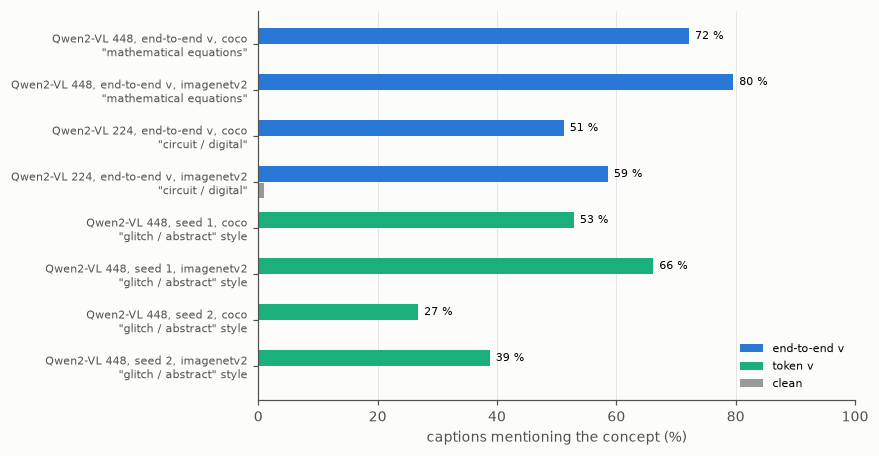

In [4]:
INJ = [('qwen2-vl-2b', own('qwen2-vl-2b', 'caption loss'), 'mathemat|equation|formula', '"mathematical equations"', BLUE),
       ('qwen2-vl-2b-224', own('qwen2-vl-2b-224', 'caption loss'), 'circuit|digital|futuristic|technolog', '"circuit / digital"', BLUE),
       ('qwen2-vl-2b', own('qwen2-vl-2b', 'seed 1'), 'glitch|abstract|surreal|pixelat|distort', '"glitch / abstract" style', AQUA),
       ('qwen2-vl-2b', own('qwen2-vl-2b', 'seed 2'), 'glitch|abstract|surreal|pixelat|distort', '"glitch / abstract" style', AQUA)]
fig, ax = plt.subplots(figsize=(7, 4.6))
labels, y = [], 0
for m, k, pat, word, col in INJ:
    for ds in ['coco', 'imagenetv2']:
        c = captions(m, ds)
        share = lambda caps: 100 * np.mean([bool(re.search(pat, s, re.I)) for s in caps])
        ax.barh(y + 0.18, share(c[k]), 0.34, color=col); ax.barh(y - 0.18, share(c['clean']), 0.34, color=GRAY)
        ax.text(share(c[k]) + 1, y + 0.18, '%.0f %%' % share(c[k]), va='center', fontsize=7.5)
        labels.append('%s, %s, %s\n%s' % (NAMES[m], k.split('), ')[-1] if 'seed' in k else 'end-to-end v', ds, word))
        y -= 1
ax.set_yticks(np.arange(0, y, -1), labels, fontsize=7); ax.set_xlim(0, 100)
ax.set_xlabel('captions mentioning the concept (%)'); ax.grid(axis='x', color=GRID); ax.grid(axis='y', visible=False)
ax.barh(0, 0, 0, color=BLUE, label='end-to-end v'); ax.barh(0, 0, 0, color=AQUA, label='token v')
ax.barh(0, 0, 0, color=GRAY, label='clean'); ax.legend(fontsize=7.5, loc='lower right')
plt.show()

## ImageNet accuracy read from the captions

A metric independent of the 0.5 threshold: each caption of the 500 held-out images is matched (MiniLM) against "a photo of a <class>" for the 1,000 ImageNet classes; top-1 against the true class. Computed by `python imagenet_accuracy.py` (reads the saved captions). Captions are short and generic, so absolute values are low; compare conditions within a model, not with a classifier.

In [5]:
acc = json.load(open(RESULTS_DIR / 'imagenet_accuracy.json'))
rows = []
for m in ENC + REAL:
    a = acc[m]
    get = lambda k: '%.1f %%' % a[k]['top1'] if k in a else '—'
    rows.append([NAMES[m], get('clean'), get(own(m)), get(own(m, 'caption loss')), get('random ±xi')])
show_table(['model', 'clean', 'token v (seed 0)', 'end-to-end v', 'noise ±ξ'], rows, 'top-1 accuracy, ImageNetV2 held-out (±4 points)')

**top-1 accuracy, ImageNetV2 held-out (±4 points)**

| model | clean | token v (seed 0) | end-to-end v | noise ±ξ |
|---|---|---|---|---|
| SigLIP | 14.4 % | 9.2 % | 7.8 % | 15.0 % |
| CLIP | 7.6 % | 3.4 % | 4.8 % | 8.0 % |
| I-JEPA | 5.2 % | 1.8 % | 4.0 % | 4.4 % |
| MAE | 5.0 % | 0.4 % | 1.0 % | 5.6 % |
| SmolVLM-256M | 14.8 % | 1.0 % | 12.8 % | 14.4 % |
| LLaVA-OV-0.5B | 36.4 % | 11.0 % | — | 35.2 % |
| Qwen2-VL 448 | 42.8 % | 38.6 % | 34.6 % | 43.6 % |
| Qwen2-VL 224 | 41.2 % | 31.2 % | 31.8 % | 37.6 % |

The ranking of the models is the same as with "changed". For Qwen2-VL the class is still often named under attack while a foreign concept or style is added, consistent with injection (report VIII.1).

**Limits.** Word-level search: no paraphrases, no multi-word concepts; arbitrary (but pre-set) thresholds; mode classification by hand.